In [119]:
# import system libraries
import logging
import sys, copy
# import scientific libraries
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from scipy.interpolate import InterpolatedUnivariateSpline as spline
import h5py
import pandas as pd
# import data analysis libraries
from ldc.waveform.lisabeta import FastBHB
import lisabeta.lisa.lisa as lisa

from ldc.lisa.noise import AnalyticNoise, get_noise_model
from chainconsumer import Chain, ChainConsumer, make_sample, Truth
import lisaconstants
# import sampler libraries
from eryn.ensemble import EnsembleSampler
from eryn.state import State
from eryn.prior import uniform_dist, ProbDistContainer

from lisabeta.lisa.lisa import EvaluateTDIFreqseries
import lisabeta.tools.pyspline as pyspline
import lisabeta.lisa.lisatools as lisatools
import lisabeta.tools.pytools as pytools
from ldc.common import tools
from ldc.waveform.waveform import HpHc
import scipy.signal



mpl.rcParams.update(mpl.rcParamsDefault)

# Set up injection and find noiseless Afull and Efull. Set up Npsd, timing, and frequencies

In [120]:
#imports all dependencies and homebrewed functions
import LISA_TTL_Functions as foc

In [121]:
'''
filename = '/Users/corinnekomlodi/Desktop/LDC2_sangria_training_v2.h5'
catpath = 'sky/mbhb/cat'
pMBHB_ldc = foc.sangria_source(filename, catpath, 2)
print(pMBHB_ldc)
pMBHB_ldc['Distance'] = pMBHB_ldc['Distance']*10
#pMBHB_ldc['Distance'] = 2500
print(pMBHB_ldc)
'''

"\nfilename = '/Users/corinnekomlodi/Desktop/LDC2_sangria_training_v2.h5'\ncatpath = 'sky/mbhb/cat'\npMBHB_ldc = foc.sangria_source(filename, catpath, 2)\nprint(pMBHB_ldc)\npMBHB_ldc['Distance'] = pMBHB_ldc['Distance']*10\n#pMBHB_ldc['Distance'] = 2500\nprint(pMBHB_ldc)\n"

In [122]:
#set up the injection
#'''
pMBHB_ldc = {'EclipticLatitude': -0.30300442294174235,
 'EclipticLongitude': 1.2925183861048521,
 'PolarAngleOfSpin1': 1.2031361791056812,
 'PolarAngleOfSpin2': 2.097303543065685,
 'Spin1': 0.747377,
 'Spin2': 0.8388,
 'Mass1': 1323277.47932, #original 1323277.47932
 'Mass2': 612485.5060299999, #original 612485.5060299999
 'CoalescenceTime': 11526944.921879262,
 'PhaseAtCoalescence': 1.2201968860015653,
 'InitialPolarAngleL': 2.6919824500032945,
 'InitialAzimuthalAngleL': 1.808398497592109,
 'Redshift': 1.73941,
 'Distance': 2500, #13470.983559 original
 'ObservationDuration': 31558149.763545603, # 1.0007023643945205 years
 'Cadence': 3.0}
 #'''

snr = 22295 for distance 1347.983559 \
snr = 223 for distance 134700 \
snr = 12021 for distance 2500 \
snr = 2230 for distance 13470 \
snr = 7026 for mass x10 distance 2500 \
snr = 1303 for mass x10 distance 13470 \
snr = 130 for mass x10 distance 134700 \
snr = 2096 for mass x.1 distance 2500 \
snr = 389 for mass x0.1 distance 13470 \
snr = 38 for mass x0.1 distance 134700

In [123]:
save_name = 'XYZtest'

still need to run:

In [124]:
#establish t_min, max, separation and number of samples
t_min = 0
t_max = pMBHB_ldc["CoalescenceTime"]+1000
dt = 0.25
df = 1/t_max

t = np.arange(t_min, t_max, dt)

In [125]:
#set up the injection in lisabeta terms
FBH = FastBHB("MBHB", T=t_max, delta_t=dt, approx="IMRPhenomHM")
pMBHB = FBH.rename_as_lisabeta(pMBHB_ldc)

pMBHB['psi'] += np.pi
pMBHB['phi'] -= np.pi
#print(pMBHB)

In [126]:
#background settings
waveform_params_smbh = {
    "minf": 1e-5,
    "maxf": 1,
    "t0": 0.0,
    "timetomerger_max": 1.0,
    "tmax": 1.0,
    "TDI": "TDI2AET",
    "LISAconst": "Proposal",
    "responseapprox": "full",
    "frozenLISA": False,
    "TDIrescaled": False,
    "modes": None,
    # Waveform approximant and set of harmonics to use 
    "approximant": "IMRPhenomHM"
}

# Standard frequency vector between min and max [1e-5,1] with no zero allowed

In [127]:
#Fvec for interpolation
fmin = 1e-5
fmax = 1
ndata = int(t_max/dt)
df = 1/t_max

# Get the full frequencies
if (ndata % 2)==0:              # Get the number of frequencies
    nfft = int((ndata/2)+1)
else:
    nfft = int((ndata+1)/2)

F = df*nfft                 # make the positive frequency vector
fvec = np.arange(0, F, df)

# Get the frequencies of interest
f_inds = np.where(np.logical_and(fvec >= fmin, fvec < fmax))
fvec = fvec[f_inds]
fvec = fvec[fvec>0]
print(len(fvec))

11527829


In [128]:
#fvec_coarse = fvec[::8000]  
#print(len(fvec_coarse))

In [129]:
#downsample fvec
if len(fvec) != 1441:
    fvec = fvec[::8000]  
    fvec = np.ascontiguousarray(fvec)
else:
    pass

print(len(fvec))

1441


In [130]:
df = fvec[1]-fvec[0]

## Generating A/E/T and X/Y/Z Full

In [ ]:
#generate data
tdisignal = lisa.GenerateLISATDISignal_SMBH(pMBHB, 
                                            gridfreq = fvec,
                                            **waveform_params_smbh)
tdi = tdisignal['tdi']

modesf  = tdisignal['tdi']['modes']
colors = ['red', 'blue', 'purple', 'magenta', 'green', 'gray']
print(modesf)
A_full = np.zeros(len(fvec), dtype=complex)
E_full = np.zeros(len(fvec), dtype=complex)
T_full = np.zeros(len(fvec), dtype=complex)

for i in range(len(modesf)):
    mbh_lb = tdi[modesf[i]]

    mask = (fvec >= mbh_lb['freq'].min()) & (fvec <= mbh_lb['freq'].max())
    
    #phase
    splPh = spline(mbh_lb['freq'], mbh_lb['phase'], ext='raise')
    #A
    splAr = spline(mbh_lb['freq'], mbh_lb['amp_real_chan1'])
    splAi = spline(mbh_lb['freq'], mbh_lb['amp_imag_chan1'])
    #E
    splEr = spline(mbh_lb['freq'], mbh_lb['amp_real_chan2'])
    splEi = spline(mbh_lb['freq'], mbh_lb['amp_imag_chan2'])
    #E
    splTr = spline(mbh_lb['freq'], mbh_lb['amp_real_chan3'])
    splTi = spline(mbh_lb['freq'], mbh_lb['amp_imag_chan3'])

    #plot partials
    print(np.where(fvec == min(fvec[mask])))
    A_partial = np.conjugate((splAr(fvec[mask]) + 1.j*splAi(fvec[mask])) * np.exp(1j*splPh(fvec[mask])))
    E_partial = np.conjugate((splEr(fvec[mask]) + 1.j*splEi(fvec[mask])) * np.exp(1j*splPh(fvec[mask])))
    T_partial = np.conjugate((splTr(fvec[mask]) + 1.j*splTi(fvec[mask])) * np.exp(1j*splPh(fvec[mask])))

    plt.loglog(fvec[mask], np.abs(A_partial)**2, label = str(modesf[i]), color = colors[i])
    plt.loglog(fvec[mask], np.abs(E_partial)**2, '--', color = colors[i])
    plt.legend()

    A_full[mask] += A_partial
    E_full[mask] += E_partial
    T_full[mask] += T_partial

Nmodel = AnalyticNoise(fvec, model="SciRDv1") # or whatever version you prefer. In the previous notebook we used "sangria"
Npsd = Nmodel.psd(option='A', tdi2=True)
Npsd_X = Nmodel.psd(option='X', tdi2=True)
Npsd_XY = Nmodel.psd(option='XY', tdi2=True)

def invNpsd(XX, XY): #This changes if arm lengths are non equal
    diagonalNpsd = (XX+XY)/(XX**2+XX*XY-2*XY**2)
    offdiagNpsd = -XY/(XX**2+XX*XY-2*XY**2)
    return diagonalNpsd, offdiagNpsd

diagn, offdiagn = invNpsd(Npsd_X, Npsd_XY)

# constructing signal at each Fouriner freq.

[(2, 2), (2, 1), (3, 3), (3, 2), (4, 4), (4, 3)]
(array([0]),)
(array([0]),)
(array([1]),)
(array([0]),)
(array([1]),)
(array([1]),)


In [132]:
Afull = A_full
Efull = E_full
Tfull = T_full

In [133]:
fig, ax = plt.subplots()
ax.loglog(fvec, np.abs(Afull)**2, label = 'Afull, No TTL')
ax.loglog(fvec, Npsd, '--', color = 'k', label = 'Npsd')
ax.set_xlabel('Frequency')
ax.set_ylabel('PSD')
ax.legend(loc = 'lower left')
ax.grid()


# Set up the MCMC: array for trials, likelihood, priors, initial condition, temps, walkers, samples, etc

In [134]:
#now we set things up for mcmc
#solving for chirpmass and ratio
m1 = pMBHB['m1']
m2 = pMBHB['m2']
q = m1/m2
Mc = (m1+m2)*(q/(1+q)**2)**0.6

src0 = pMBHB.copy()
src0["Mchirp"] = Mc
src0["q"] = q
del src0["m1"]
del src0["m2"]

keys = src0.keys()

#create the array to be altered in likelihood
#src = copy.deepcopy(src0)
print(pMBHB)
print(src0)

#Fix the things that rely on pi
#src0['phi'] = np.mod(src0['phi'], np.pi)
#src0['psi'] = np.mod(src0['psi'], np.pi)
print(src0)

{'beta': -0.30300442294174235, 'lambda': 1.2925183861048521, 'chi1': np.float64(0.26863190922667673), 'chi2': np.float64(-0.4215109787709388), 'm1': 1323277.47932, 'm2': 612485.5060299999, 'Deltat': 11526944.921879262, 'phi': -1.9213957675882278, 'dist': 2500, 'psi': np.float64(1.2912226019238924), 'inc': np.float64(2.2517895222056112)}
{'beta': -0.30300442294174235, 'lambda': 1.2925183861048521, 'chi1': np.float64(0.26863190922667673), 'chi2': np.float64(-0.4215109787709388), 'Deltat': 11526944.921879262, 'phi': -1.9213957675882278, 'dist': 2500, 'psi': np.float64(1.2912226019238924), 'inc': np.float64(2.2517895222056112), 'Mchirp': 772462.8571528315, 'q': 2.160504152820206}
{'beta': -0.30300442294174235, 'lambda': 1.2925183861048521, 'chi1': np.float64(0.26863190922667673), 'chi2': np.float64(-0.4215109787709388), 'Deltat': 11526944.921879262, 'phi': -1.9213957675882278, 'dist': 2500, 'psi': np.float64(1.2912226019238924), 'inc': np.float64(2.2517895222056112), 'Mchirp': 772462.85715

In [135]:
def AETtoXYZ(A, E, T):
    X = (1/6)*(-3*np.sqrt(2)*A + np.sqrt(6)*E + 2*np.sqrt(3)*T)
    Y = (1/3)*(-np.sqrt(6)*E + np.sqrt(3)*T)
    Z = (1/6)*(3*np.sqrt(2)*A + np.sqrt(6)*E + 2*np.sqrt(3)*T)
    return X, Y, Z

In [136]:
DA = Afull.copy()
DE = Efull.copy()
DT = Tfull.copy()

DX, DY, DZ = AETtoXYZ(DA, DE, DT)

In [ ]:
'''
#Interpolated likelihood
def likelihood_interp(pvector):
    src = {k: v for k, v in zip(keys, pvector)}

    tdisignal = lisa.GenerateLISATDISignal_SMBH(src, 
                                                gridfreq=fvec, 
                                                **waveform_params_smbh)
    modesf = tdisignal['tdi']['modes']

    df = fvec[1]-fvec[0]

    hA = np.zeros(len(fvec), dtype=complex)
    hE = np.zeros(len(fvec), dtype=complex)

    for i in range(len(modesf)):
        mbh_lb = tdisignal['tdi'][modesf[i]]

        mask = (fvec >= mbh_lb['freq'].min()) & (fvec <= mbh_lb['freq'].max())
        
        #phase
        splPh = spline(mbh_lb['freq'], mbh_lb['phase'], ext='raise')
        #A
        splAr = spline(mbh_lb['freq'], mbh_lb['amp_real_chan1'])
        splAi = spline(mbh_lb['freq'], mbh_lb['amp_imag_chan1'])
        #E
        splEr = spline(mbh_lb['freq'], mbh_lb['amp_real_chan2'])
        splEi = spline(mbh_lb['freq'], mbh_lb['amp_imag_chan2'])

        A_partial = np.conjugate((splAr(fvec[mask]) + 1.j*splAi(fvec[mask])) * np.exp(1j*splPh(fvec[mask])))
        E_partial = np.conjugate((splEr(fvec[mask]) + 1.j*splEi(fvec[mask])) * np.exp(1j*splPh(fvec[mask])))

        hA[mask] += A_partial
        hE[mask] += E_partial

    SN_m = 4.0 * df * np.sum(np.real(DA * np.conjugate(hA)) / Npsd) + 4.0 * df * np.sum(np.real(DE * np.conjugate(hE)) / Npsd)

    XX = 4.0 * df * np.sum(np.abs(hA)**2 / Npsd) + 4.0 * df * np.sum(np.abs(hE)**2 / Npsd)

    loglik = SN_m - 0.5*XX

    return loglik#, hA
'''

"\n#Interpolated likelihood\ndef likelihood_interp(pvector):\n    src = {k: v for k, v in zip(keys, pvector)}\n\n    tdisignal = lisa.GenerateLISATDISignal_SMBH(src, \n                                                gridfreq=fvec, \n                                                #scale_freq_hm=False,\n                                                **waveform_params_smbh)\n    modesf = tdisignal['tdi']['modes']\n\n    df = fvec[1]-fvec[0]\n\n    hA = np.zeros(len(fvec), dtype=complex)\n    hE = np.zeros(len(fvec), dtype=complex)\n\n    for i in range(len(modesf)):\n        mbh_lb = tdisignal['tdi'][modesf[i]]\n\n        mask = (fvec >= mbh_lb['freq'].min()) & (fvec <= mbh_lb['freq'].max())\n\n        #phase\n        splPh = spline(mbh_lb['freq'], mbh_lb['phase'], ext='raise')\n        #A\n        splAr = spline(mbh_lb['freq'], mbh_lb['amp_real_chan1'])\n        splAi = spline(mbh_lb['freq'], mbh_lb['amp_imag_chan1'])\n        #E\n        splEr = spline(mbh_lb['freq'], mbh_lb['amp_real

In [138]:
def whip(a, b, Npsd):
    product = np.real(a)*np.real(b) + np.imag(a)*np.imag(b)
    arg = product*Npsd
    return arg

In [ ]:
def XYZLikelihood(pvector):
    #Build the waveform
    src = {k: v for k, v in zip(keys, pvector)}
    
    tdisignal = lisa.GenerateLISATDISignal_SMBH(src, 
                                                gridfreq=fvec, 
                                                **waveform_params_smbh)
    modesf = tdisignal['tdi']['modes']

    df = fvec[1]-fvec[0]

    hA = np.zeros(len(fvec), dtype=complex)
    hE = np.zeros(len(fvec), dtype=complex)
    hT = np.zeros(len(fvec), dtype=complex)

    for i in range(len(modesf)):
        mbh_lb = tdisignal['tdi'][modesf[i]]

        mask = (fvec >= mbh_lb['freq'].min()) & (fvec <= mbh_lb['freq'].max())
        
        #phase
        splPh = spline(mbh_lb['freq'], mbh_lb['phase'], ext='raise')
        #A
        splAr = spline(mbh_lb['freq'], mbh_lb['amp_real_chan1'])
        splAi = spline(mbh_lb['freq'], mbh_lb['amp_imag_chan1'])

        #E
        splEr = spline(mbh_lb['freq'], mbh_lb['amp_real_chan2'])
        splEi = spline(mbh_lb['freq'], mbh_lb['amp_imag_chan2'])

        #T
        splTr = spline(mbh_lb['freq'], mbh_lb['amp_real_chan3'])
        splTi = spline(mbh_lb['freq'], mbh_lb['amp_imag_chan3'])

        A_partial = np.conjugate((splAr(fvec[mask]) + 1.j*splAi(fvec[mask])) * np.exp(1j*splPh(fvec[mask])))
        E_partial = np.conjugate((splEr(fvec[mask]) + 1.j*splEi(fvec[mask])) * np.exp(1j*splPh(fvec[mask])))
        T_partial = np.conjugate((splTr(fvec[mask]) + 1.j*splTi(fvec[mask])) * np.exp(1j*splPh(fvec[mask])))

        hA[mask] += A_partial
        hE[mask] += E_partial
        hT[mask] += T_partial

    hX, hY, hZ = AETtoXYZ(hA, hE, hT)

    #where DX/Y/Z is data and hX/Y/Z is trial
    DXX = whip(DX, hX, diagn)
    DYY = whip(DY, hY, diagn)
    DZZ = whip(DZ, hZ, diagn)
    DXY = whip(DX, hY, offdiagn) + whip(DY, hX, offdiagn)
    DXZ = whip(DX, hZ, offdiagn) + whip(DZ, hX, offdiagn)
    DYZ = whip(DY, hZ, offdiagn) + whip(DZ, hY, offdiagn)

    hXX = whip(hX, hX, diagn)
    hYY = whip(hY, hY, diagn)
    hZZ = whip(hZ, hZ, diagn)
    hXY = 2*whip(hX, hY, offdiagn)
    hXZ = 2*whip(hX, hZ, offdiagn)
    hYZ = 2*whip(hY, hZ, offdiagn)


    loglik = 4*df*(np.sum([DXX, DYY, DZZ, DXY, DXZ, DYZ])-0.5*np.sum([hXX, hYY, hZZ, hXY, hXZ, hYZ]))

    return loglik

In [140]:

day_sec = 86400

priors = {"mbh": ProbDistContainer({
    0: uniform_dist(-np.pi, np.pi), #beta
    1: uniform_dist(-np.pi/2, np.pi/2), #lambda
    2: uniform_dist(-1, 1), #chi1
    3: uniform_dist(-1, 1), #chi2
    4: uniform_dist(75*day_sec, 175*day_sec), #deltat
    5: uniform_dist(-np.pi, np.pi), #phi
    6: uniform_dist(500.0, 2000000.0), #dist 
    7: uniform_dist(0., np.pi), #psi
    8: uniform_dist(0., np.pi), #inc
    9: uniform_dist(1e4, 1e7), #mchirp 
    10: uniform_dist(1, 10), #q
})}

ndims = {"mbh": 11}


In [141]:
ntemps = 5
nwalkers = 22
nsamples = 6000
ndims = {"mbh": 11}

#a constant for noise later
fstar = 0.0190854 #c/L/(2*np.pi)

In [142]:
theta0 = np.array([[np.hstack(
          (np.random.randn(ndims["mbh"]) * 1e-8) + np.array(list(src0.values())))
          for i in range(nwalkers)]
          for _ in range(ntemps)])

start_state = State({"mbh": theta0})

In [143]:
from eryn.utils import PeriodicContainer
params = list(keys)

periodic = PeriodicContainer(

    {
        "mbh": {
            params.index("phi"): 2.0 * np.pi,
            params.index("lambda"): 2.0 * np.pi,
            params.index("psi"): np.pi,
        }
    }
)

In [144]:

sampler = EnsembleSampler(
    nwalkers,
    ndims,
    XYZLikelihood,#likelihood_interp,
    priors,
    #periodic = periodic,
    args=(),
    branch_names=["mbh"],
    tempering_kwargs=dict(ntemps=ntemps),
    nleaves_max=dict(mbh=1),
)


# Run the MCMC

In [145]:
sampler.run_mcmc(start_state, nsamples, progress=True, store = True)

 65%|██████▌   | 3903/6000 [2:45:41<2:13:24,  3.82s/it]Traceback (most recent call last):
  File "/Users/corinnekomlodi/Desktop/Robbie_UV/.venv/lib/python3.11/site-packages/eryn/ensemble.py", line 1644, in __call__
    out = self.f(*args_in, **kwargs_in)
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/mb/k18m72t149vc_bk4zdmscvxr0000gn/T/ipykernel_64983/606170327.py", line 29, in XYZLikelihood
    splEr = spline(mbh_lb['freq'], mbh_lb['amp_real_chan2'])
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/corinnekomlodi/Desktop/Robbie_UV/.venv/lib/python3.11/site-packages/scipy/interpolate/_fitpack2.py", line 755, in __init__
    if not np.all(diff(x) > 0.0):
           ^^^^^^^^^^^^^^^^^^^^^
KeyboardInterrupt
 65%|██████▌   | 3903/6000 [2:45:43<1:29:02,  2.55s/it]

eryn: Exception while calling your likelihood function:
  args added: [array([-3.02627280e-01,  1.29287629e+00,  2.68710163e-01, -4.21581033e-01,
        1.15269451e+07, -1.92206744e+00,  2.50005137e+03,  1.29150835e+00,
        2.25159062e+00,  7.72462810e+05,  2.16100945e+00])]
  args: ()
  kwargs added: {}
  kwargs: {}
  exception:


KeyboardInterrupt: 

# Plot corner and walkers

In [146]:
#define truths
keys = src0.keys()
labels = list(keys)

inj=np.array(list(src0.values()))

truths = inj.flatten()
labels_final = labels

In [147]:
truth = pd.DataFrame(data = truths , columns = ['truths'])
csv_filename_truth = save_name + "_truth.csv"
truth.to_csv(csv_filename_truth, index=False)

In [148]:
burn = 0

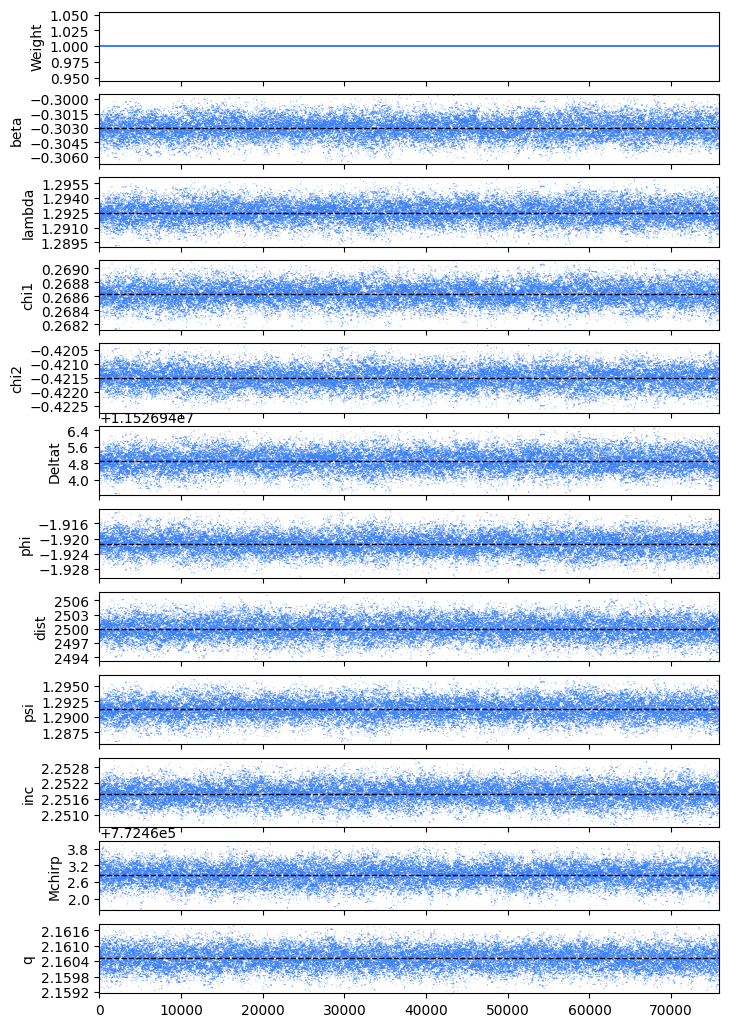

In [150]:
c = ChainConsumer()
burn = 10000

samples_2ch = sampler.get_chain()["mbh"][:, 0].reshape(-1, 11)

dfs_2chnls = pd.DataFrame(samples_2ch[burn:, :], columns = keys)

c.add_chain(Chain(samples=dfs_2chnls, name="noiseless", color="blue"))
c.add_truth(Truth(location={k:v for (k,v) in zip(labels_final,truths)}))

#import corner
#figure = corner.corner(dfs_2chnls)

c.plotter.plot()
c.plotter.plot_walks()

# Trace Plots


Full chain shape: (6000, 5, 22, 1, 11)
Coldest-chain shape used for plotting: (6000, 22, 11)


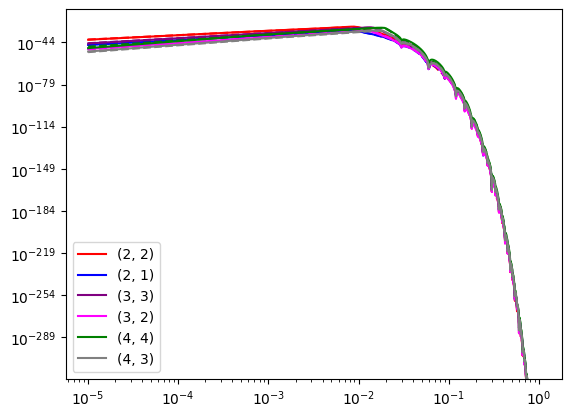

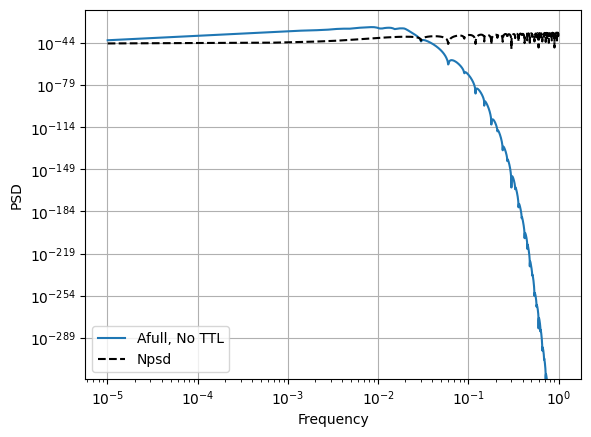

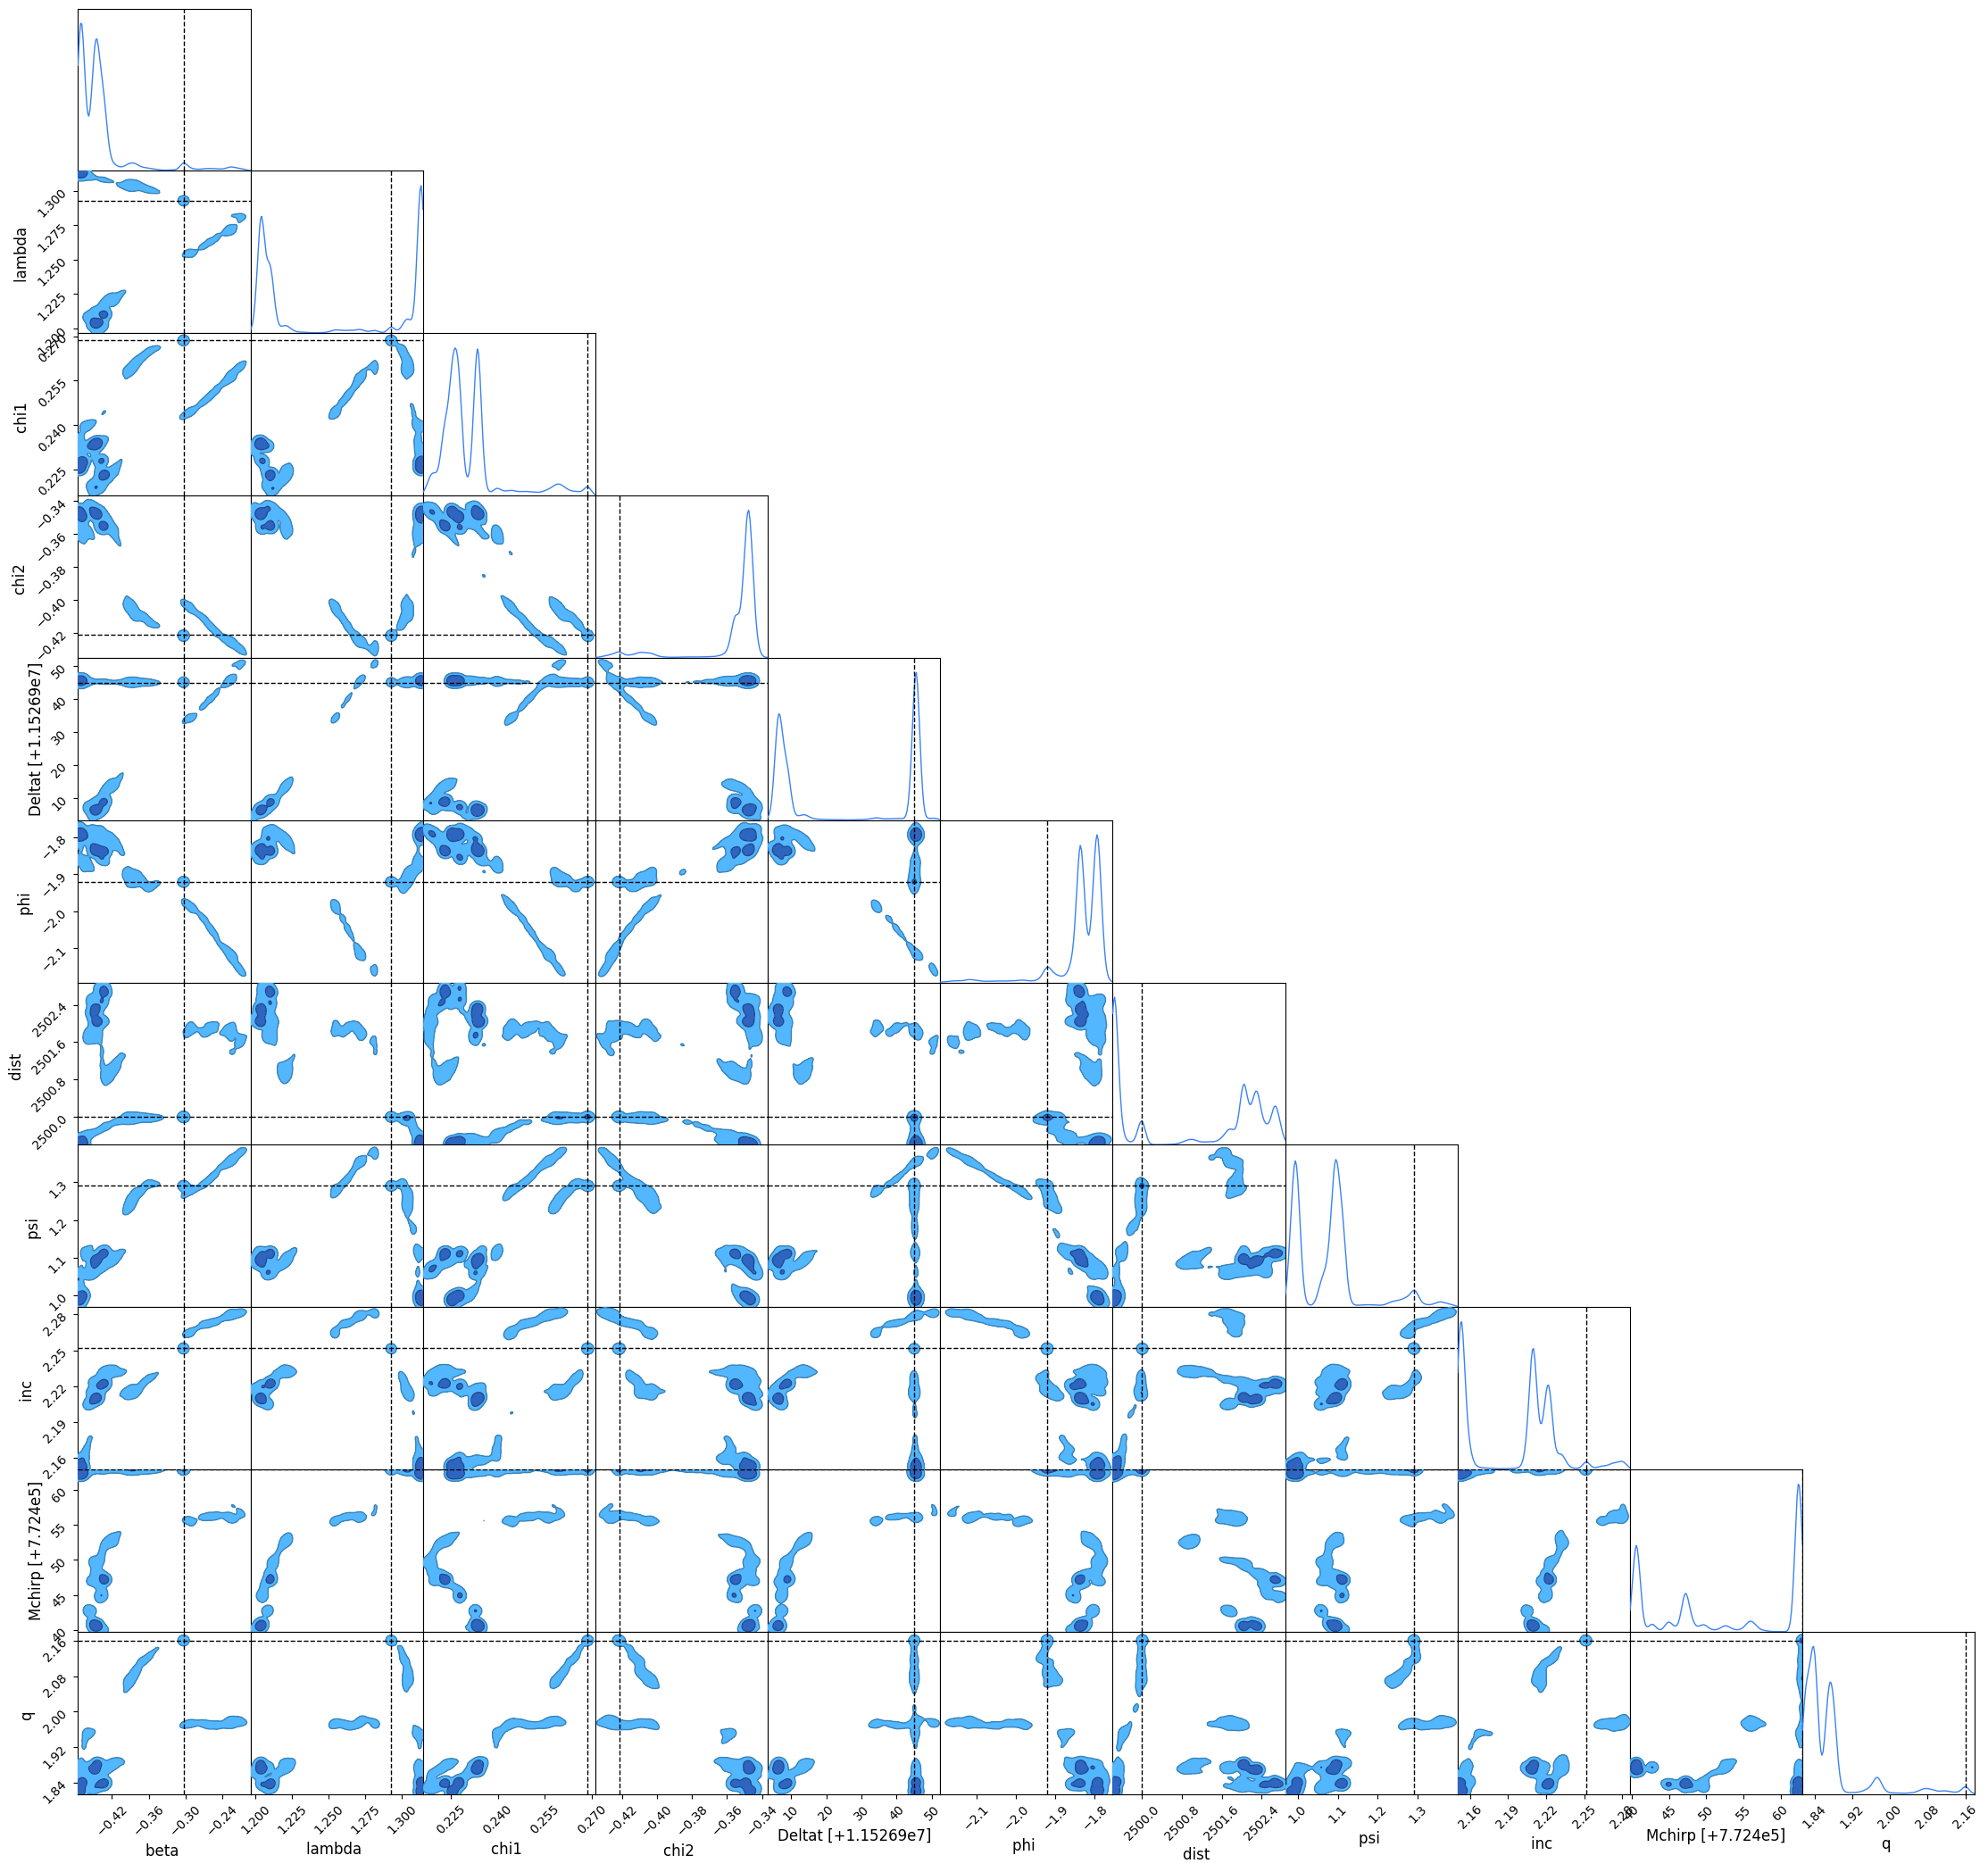

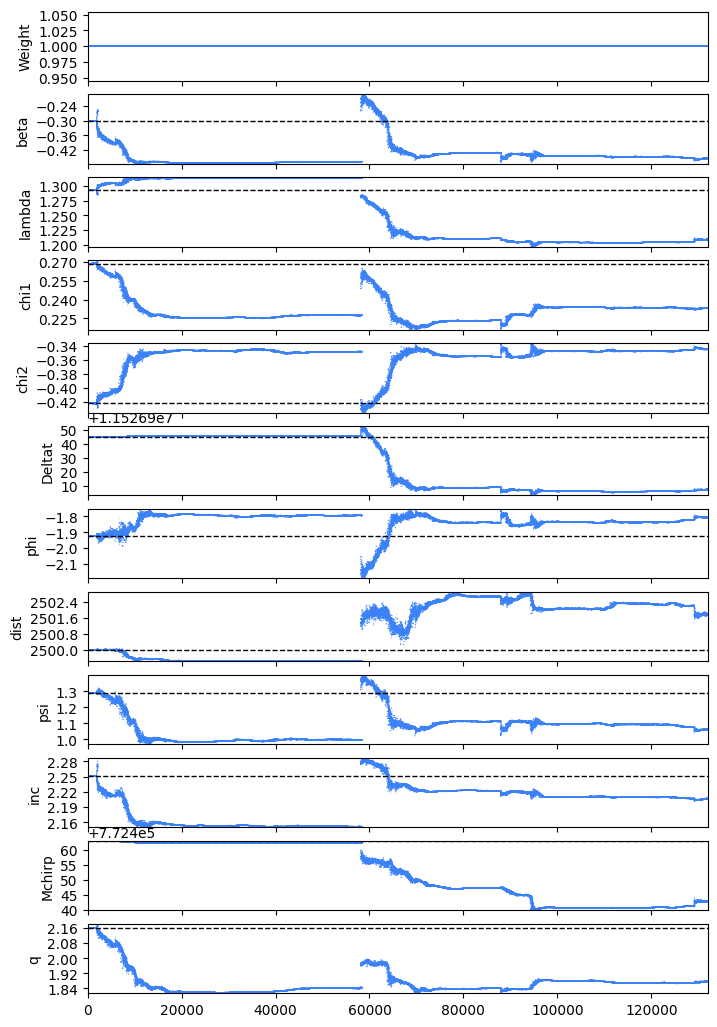

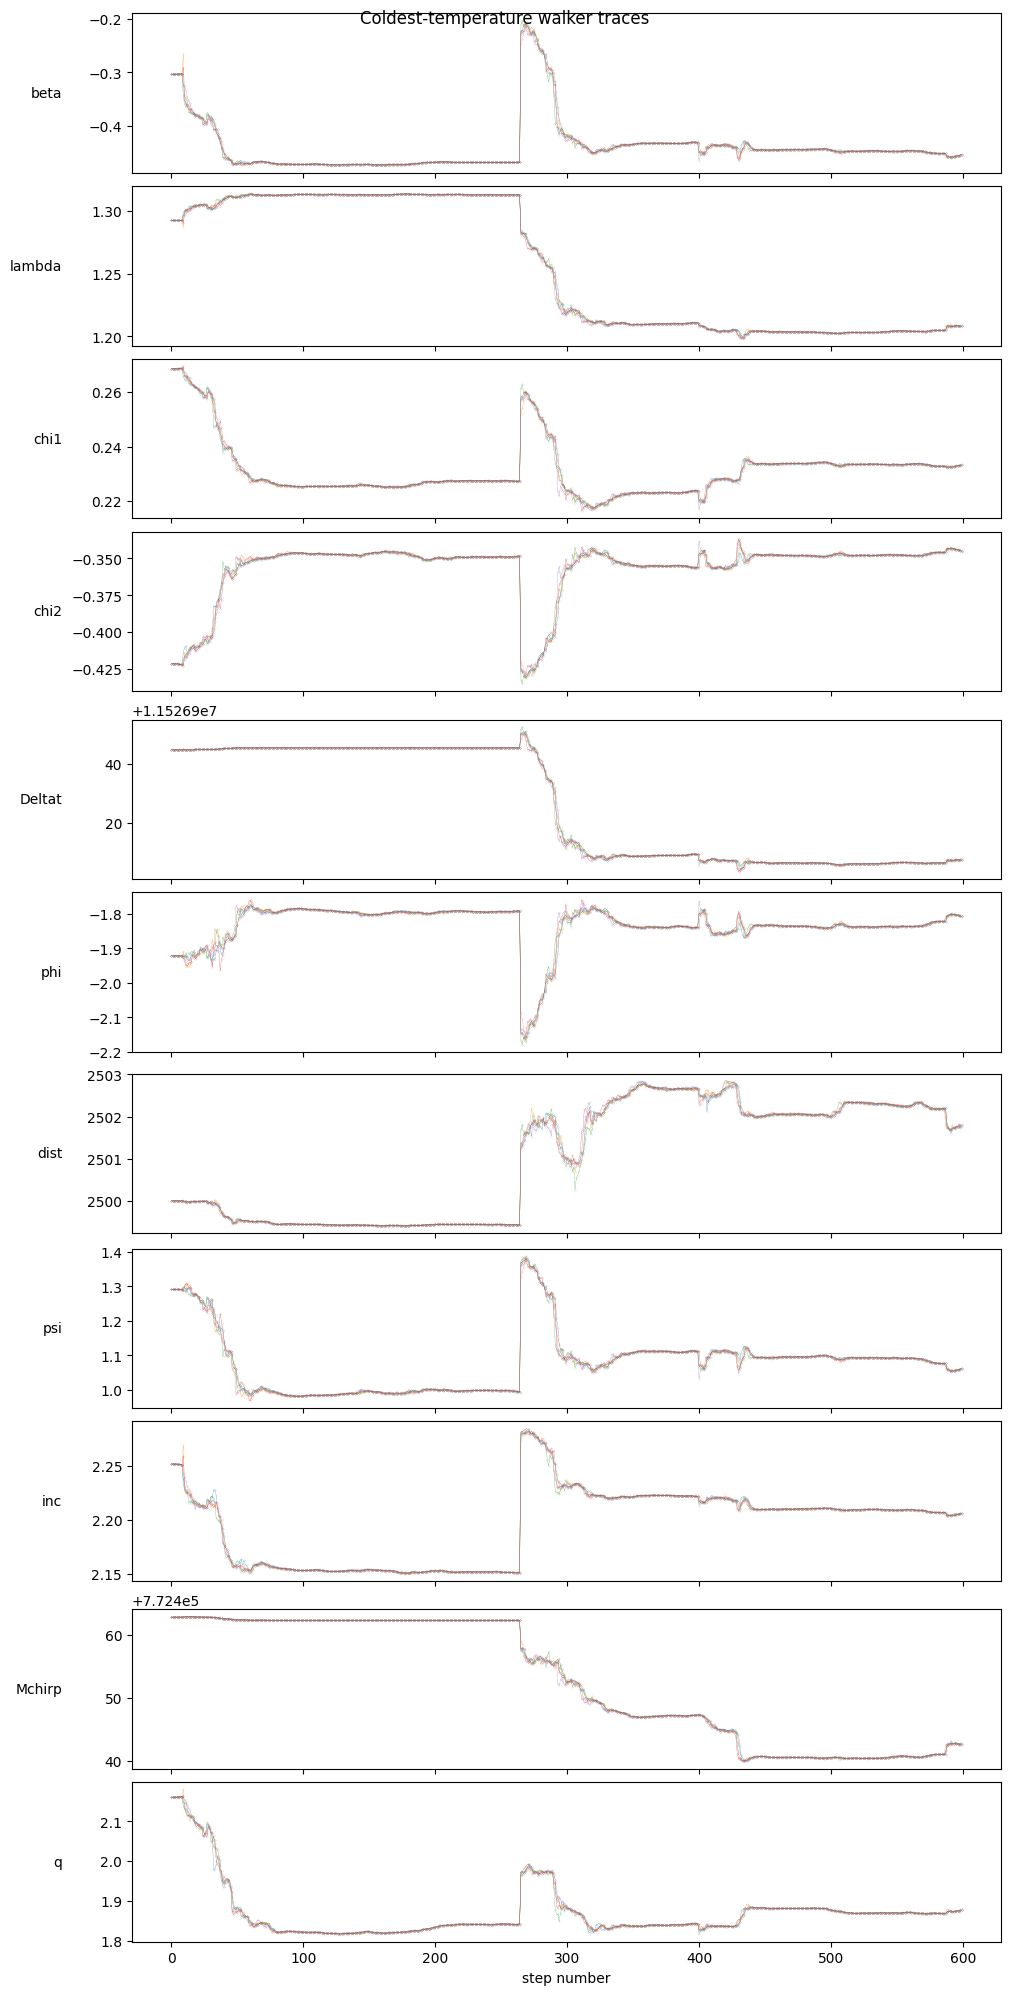

In [ ]:
"""
Per-walker trace plots for the coldest temperature chain of an Eryn MCMC run.

Uses `sampler` (an already-run eryn.ensemble.EnsembleSampler) directly,
matching the ChainConsumer-based workflow. Does NOT reshape/flatten the
walker axis away, so each walker's trajectory stays distinguishable.
"""

import numpy as np
import matplotlib.pyplot as plt

# ---- 1. Get the full chain for the "mbh" branch ----------------------------
# shape: (nsteps, ntemps, nwalkers, nleaves_max, ndim)
full_chain = sampler.get_chain()["mbh"]
#full_chain_pd = pd.DataFrame(full_chain)
print("Full chain shape:", full_chain.shape)

#csv_filename_0mm_full = "0mm_"+ save_name + "_fullchains.csv"
#full_chain_pd.to_csv(csv_filename_0mm_full, index=False)
#print(f"Chain data saved to {csv_filename_0mm_full}")

# ---- 2. Select coldest temperature (index 0 = beta=1) ----------------------
cold_chain = full_chain[:, 0]  # (nsteps, nwalkers, nleaves_max, ndim)

# Keep walkers separate. If nleaves_max == 1, just drop that axis.
# If you have multiple leaves and want each leaf's trace too, flatten
# (nwalkers, nleaves_max) together instead of picking leaf 0.
if cold_chain.shape[2] == 1:
    cold_chain = cold_chain[:, :, 0, :]        # -> (nsteps, nwalkers, ndim)
else:
    cold_chain = cold_chain[:, :, 0, :]        # or: .reshape(cold_chain.shape[0], -1, cold_chain.shape[-1])

nsteps, nwalkers, ndim = cold_chain.shape
print(f"Coldest-chain shape used for plotting: {cold_chain.shape}")

# ---- 3. Optional: discard burn-in / thin -----------------------------------
burn = 0      # e.g. 5000
thin = 1
cold_chain = cold_chain[burn::thin]
nsteps = cold_chain.shape[0]

# ---- 4. Plot trace plots ----------------------------------------------------
labels = list(src0.keys()) 

# Map each walker index to a color along a colormap
cmap = plt.get_cmap("plasma")  # try "plasma", "turbo", "cool", etc.
colors = cmap(np.linspace(0, 2, nwalkers))

fig, axes = plt.subplots(ndim, 1, figsize=(10, 1.8 * ndim), sharex=True, constrained_layout = True)

for i in range(ndim):
    ax = axes[i]
    for w in range(0,5):#nwalkers):
        ax.plot(cold_chain[:, w, i][::10], alpha=0.8, marker = '.', markersize = 0.2, lw=0.2)#, color=colors[w])
    ax.set_ylabel(labels[i], rotation=0, ha="right", va="center")
    ax.yaxis.set_label_coords(-0.08, 0.5)

axes[-1].set_xlabel("step number")
fig.suptitle("Coldest-temperature walker traces", y=1.0)

# Add a colorbar showing walker index -> color mapping
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=nwalkers - 1))
sm.set_array([])
#cbar = fig.colorbar(sm, ax=axes, location="right", fraction=0.02, pad=0.02)
#cbar.set_label("walker index")

#plt.savefig(save_name+"plot.png", dpi=150, bbox_inches="tight")
plt.show()



In [ ]:
csv_filename_0mm = "0mm_"+ save_name + "_chains.csv"
dfs_2chnls.to_csv(csv_filename_0mm, index=False)
print(f"Chain data saved to {csv_filename_0mm}")

Chain data saved to 0mm_XYZtest_chains.csv


# Add 1mm noise to the waveform

In [ ]:
#generate noise psd for 1mm
psd_sqrt = (6e-11*(np.sin(2*fvec/fstar)**2) + 1e-12)*(2*np.pi*fvec/299792458) #2.5e9 is armlength
#psd_sqrt = (6e-11*(np.sin(2*fvec/fstar)**2) + 1e-12)*(2*np.pi*df/3e8)

#1mm eyeball -> 6e-11
#2mm eyeball -> 2e-10
#psd = ((6e-11*(np.sin(2*fvec/fstar)**2) + 1e-12)/2.5e9)**2/(df*4)

#Add noise function
def randc(r):
    #fix seed
    np.random.seed(42)
    return r/np.sqrt(2)*(np.random.rand(*r.shape) + 1j*np.random.rand(*r.shape))

def randE(r):
    #fix seed
    np.random.seed(24)
    return r/np.sqrt(2)*(np.random.rand(*r.shape) + 1j*np.random.rand(*r.shape))


In [ ]:

#generate noise
noise_fft_A_1 = randc(psd_sqrt)
noise_fft_A = randc(psd_sqrt)
noise_fft_E_1 = randE(psd_sqrt)
noise_fft_E = randE(psd_sqrt)

#add noisy noise to signal
Afull = A_full+ noise_fft_A/np.sqrt(df*4)
Efull = E_full+ noise_fft_E/np.sqrt(df*4)

A_full_1 = Afull
E_full_1 = Efull

In [ ]:
DA = Afull.copy()
DE = Efull.copy()

In [ ]:
fig1, ax1 = plt.subplots()
ax1.loglog(fvec, np.abs(A_full)**2, label = 'Afull, No TTL')
ax1.loglog(fvec, np.abs(Afull)**2, label = 'Afull, TTL')
ax1.loglog(fvec, np.abs(noise_fft_A)**2, label = 'TTL')
ax1.loglog(fvec, Npsd, '--', color = 'k', label = 'Npsd')
#ax1.loglog(fvec, psd, color = 'silver' ,label = 'TTL psd')
ax1.set_xlabel('Frequency')
ax1.set_ylabel('PSD')
ax1.set_ylim([1e-50,1e-30])
ax1.legend(loc = 'lower center')
ax1.grid()

# Rerun the same MCMC with 1mm

In [ ]:
sampler2 = EnsembleSampler(
    nwalkers,
    ndims,
    XYZLikelihood,#likelihood_interp,
    priors,
    args=(),
    branch_names=["mbh"],
    tempering_kwargs=dict(ntemps=ntemps),
    nleaves_max=dict(mbh=1),
)

In [ ]:
sampler2.run_mcmc(start_state, nsamples, progress=True, store = True)

100%|██████████| 6000/6000 [3:39:53<00:00,  2.20s/it]  


# Plot walkers and corners 1mm

Parameter phi in chain 1mm is not constrained
Parameter dist in chain 1mm is not constrained
Parameter psi in chain 1mm is not constrained


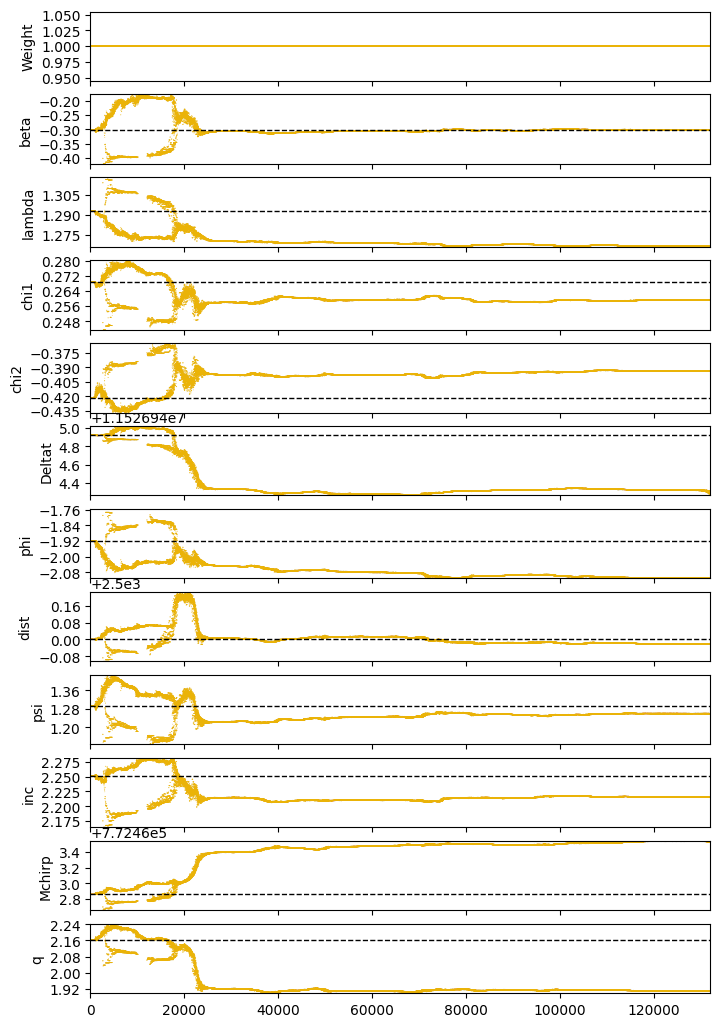

In [ ]:
a = ChainConsumer()
burn = 0
one_samples = sampler2.get_chain()["mbh"][:, 0].reshape(-1, 11)

#burn = 30000
one_samp= pd.DataFrame(one_samples[burn:, :], columns = keys)

a.add_chain(Chain(samples=one_samp, name="1mm", color="yellow"))
a.add_truth(Truth(location={k:v for (k,v) in zip(labels_final,truths)}))

a.plotter.plot()
a.plotter.plot_walks()

In [ ]:
csv_filename_1mm = "1mm_"+ save_name + "_chains.csv"
one_samp.to_csv(csv_filename_1mm, index=False)
print(f"Chain data saved to {csv_filename_1mm}")

Chain data saved to 1mm_XYZtest_chains.csv


# Add 2mm noise to the waveform

In [ ]:
#generate noise psd for 1mm
psd_sqrt = (2e-10*(np.sin(2*fvec/fstar)**2) + 1e-12)*(2*np.pi*fvec/299792458)#2.5e9 is armlength
#1mm eyeball -> 6e-11
#2mm eyeball -> 2e-10

noise_fft_A_2 = randc(psd_sqrt)
noise_fft_A = randc(psd_sqrt)
noise_fft_E_2 = randE(psd_sqrt)
noise_fft_E = randE(psd_sqrt)

#add noisy noise to signal
Afull = A_full+ noise_fft_A/np.sqrt(df*4)
Efull = E_full+ noise_fft_E/np.sqrt(df*4)

A_full_2 = Afull
E_full_2 = Efull

In [ ]:
fig2, ax2 = plt.subplots()
ax2.loglog(fvec, np.abs(A_full_2)**2, label = 'Afull, 2.3 TTL')
ax2.loglog(fvec, np.abs(A_full_1)**2, label = 'Afull, 1 TTL')
ax2.loglog(fvec, np.abs(A_full)**2, label = 'A_full, no TTL')
#ax2.loglog(fvec, np.abs(noise_fft_A/np.sqrt(df*4))**2, label = 'noise_fft_A')
ax2.loglog(fvec, Npsd/(df*4), '--', color = 'k', label = 'Npsd')
ax2.set_xlabel('Frequency')
ax2.set_ylabel('PSD')
ax2.legend(loc = 'upper left')
ax2.set_ylim([10e-43, 10e-32])
ax2.grid()

In [ ]:
DA = Afull.copy()
DE = Efull.copy()

# Rerun the same MCMC with 2.3 mm

In [ ]:
sampler3 = EnsembleSampler(
    nwalkers,
    ndims,
    XYZLikelihood,#likelihood_interp,
    priors,
    args=(),
    branch_names=["mbh"],
    tempering_kwargs=dict(ntemps=ntemps),
    nleaves_max=dict(mbh=1),
)

In [ ]:
sampler3.run_mcmc(start_state, nsamples, progress=True, store = True)

100%|██████████| 6000/6000 [3:39:03<00:00,  2.19s/it]  


# Corners and Chains for 2.3 mm

In [ ]:
#define truths
keys = src0.keys()
labels = list(keys)

inj=np.array(list(src0.values()))

truths = inj.flatten()
labels_final = labels

Parameter phi in chain 2.3 mm/rad is not constrained
Parameter dist in chain 2.3 mm/rad is not constrained
Parameter psi in chain 2.3 mm/rad is not constrained


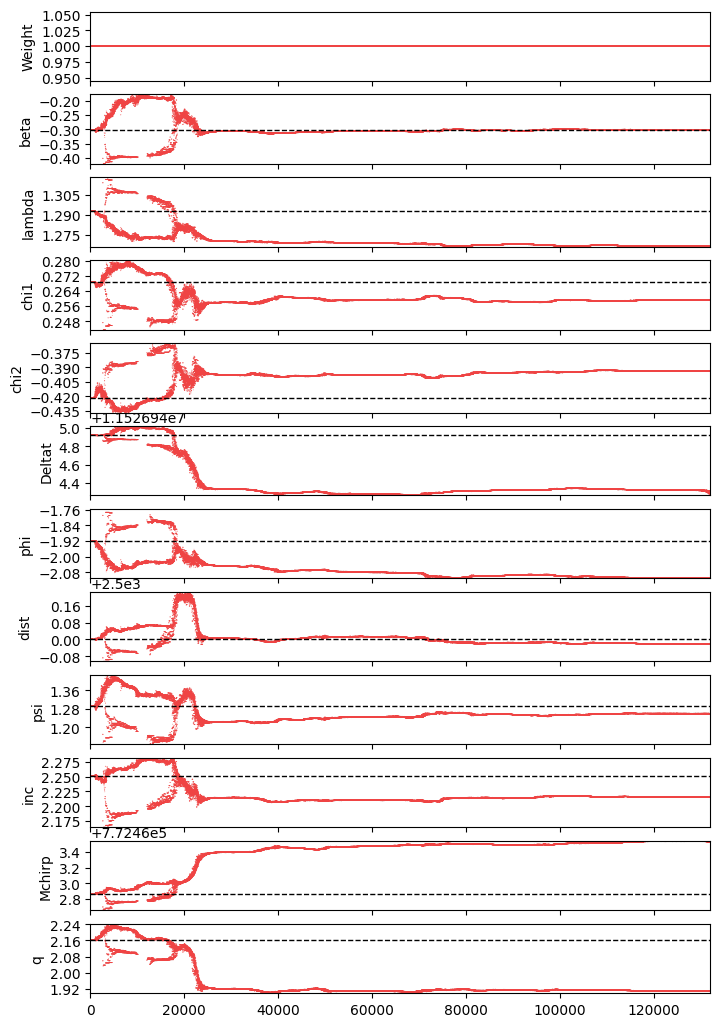

In [ ]:
b = ChainConsumer()
burn = 0000
two_samples = sampler3.get_chain()["mbh"][:, 0].reshape(-1, 11)

#burn = 800000
two_samp= pd.DataFrame(two_samples[burn:, :], columns = keys)

b.add_chain(Chain(samples=two_samp, name="2.3 mm/rad", color="red"))
b.add_truth(Truth(location={k:v for (k,v) in zip(labels_final,truths)}))

b.plotter.plot()
b.plotter.plot_walks()

In [ ]:
'''
log = ChainConsumer()
loglik = sampler3.get_log_like()#["mbh"][:, 0].reshape(-1, 11)
loglik = loglik[:, 0]
loglik = pd.DataFrame(loglik, columns = keys)
print(loglik.shape)
log.add_chain(Chain(samples=loglik, name="log likelihood 2.3", color="red"))
log.plotter.plot_walks()
'''

'\nlog = ChainConsumer()\nloglik = sampler3.get_log_like()#["mbh"][:, 0].reshape(-1, 11)\nloglik = loglik[:, 0]\nloglik = pd.DataFrame(loglik, columns = keys)\nprint(loglik.shape)\nlog.add_chain(Chain(samples=loglik, name="log likelihood 2.3", color="red"))\nlog.plotter.plot_walks()\n'

In [ ]:
csv_filename_2mm = "2mm_"+ save_name + "_chains.csv"
two_samp.to_csv(csv_filename_2mm, index=False)
print(f"Chain data saved to {csv_filename_2mm}")

Chain data saved to 2mm_XYZtest_chains.csv


# Let'd do a small checkin with those three chains

Parameter beta in chain noiseless is not constrained
Parameter lambda in chain noiseless is not constrained
Parameter lambda in chain 1 mm/rad is not constrained
Parameter lambda in chain 2.3 mm/rad is not constrained
Parameter chi1 in chain noiseless is not constrained
Parameter chi2 in chain 1 mm/rad is not constrained
Parameter chi2 in chain 2.3 mm/rad is not constrained
Parameter Deltat in chain noiseless is not constrained
Parameter Deltat in chain 1 mm/rad is not constrained
Parameter Deltat in chain 2.3 mm/rad is not constrained
Parameter phi in chain noiseless is not constrained
Parameter phi in chain 1 mm/rad is not constrained
Parameter phi in chain 2.3 mm/rad is not constrained
Parameter dist in chain noiseless is not constrained
Parameter psi in chain noiseless is not constrained
Parameter inc in chain noiseless is not constrained
Parameter inc in chain 1 mm/rad is not constrained
Parameter inc in chain 2.3 mm/rad is not constrained
Parameter Mchirp in chain noiseless is no

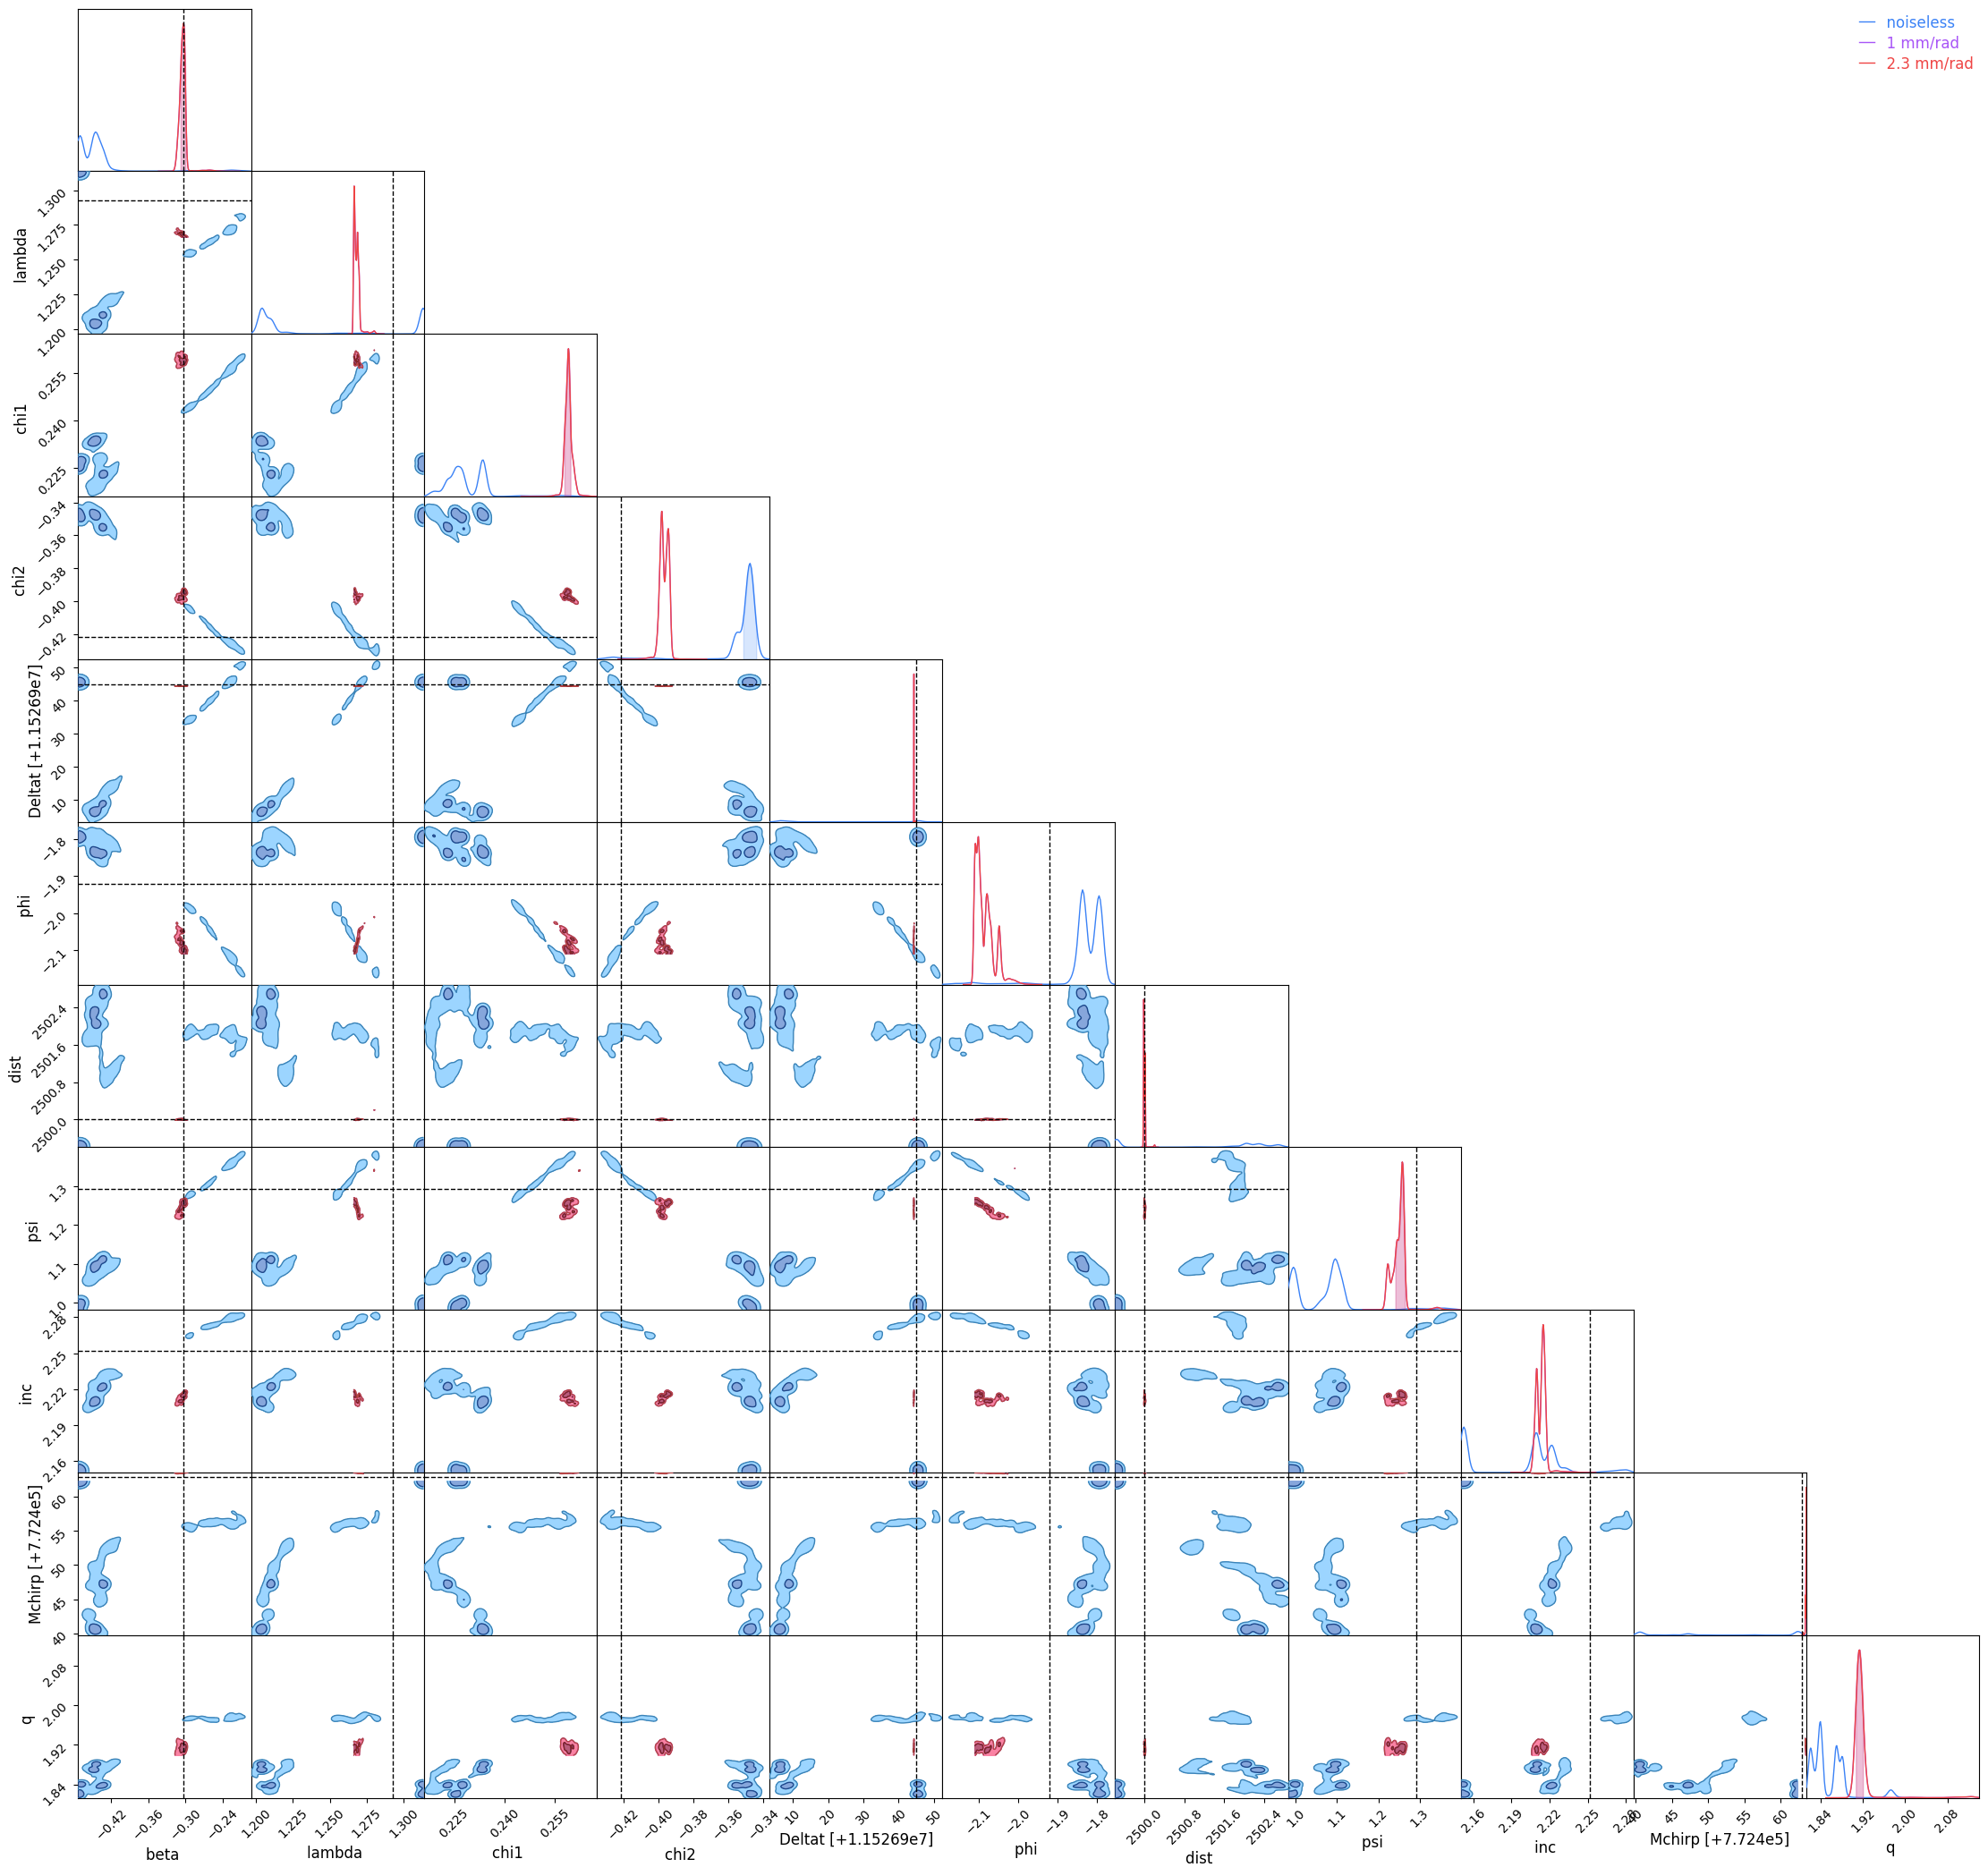

In [ ]:
check = ChainConsumer()
burn = 20000
check.add_chain(Chain(samples=dfs_2chnls[burn:], name="noiseless", color="blue"))
check.add_chain(Chain(samples=one_samp[burn:], name="1 mm/rad", color="purple"))
check.add_chain(Chain(samples=two_samp[burn:], name="2.3 mm/rad", color="red"))
check.add_truth(Truth(location={k:v for (k,v) in zip(labels_final,truths)}))

check.plotter.plot()
#check.plotter.plot_walks()

# Checking noise realization

In [ ]:
def likelihood_interp_trial(pvector):
    src = {k: v for k, v in zip(keys, pvector)}

    tdisignal = lisa.GenerateLISATDISignal_SMBH(src, 
                                                gridfreq=fvec, 
                                                #scale_freq_hm=False,
                                                **waveform_params_smbh)
    modesf = tdisignal['tdi']['modes']

    df = fvec[1]-fvec[0]

    hA = np.zeros(len(fvec), dtype=complex)
    hE = np.zeros(len(fvec), dtype=complex)

    for i in range(len(modesf)):
        mbh_lb = tdisignal['tdi'][modesf[i]]

        mask = (fvec >= mbh_lb['freq'].min()) & (fvec <= mbh_lb['freq'].max())
        
        #phase
        splPh = spline(mbh_lb['freq'], mbh_lb['phase'], ext='raise')
        #A
        splAr = spline(mbh_lb['freq'], mbh_lb['amp_real_chan1'])
        splAi = spline(mbh_lb['freq'], mbh_lb['amp_imag_chan1'])
        #E
        splEr = spline(mbh_lb['freq'], mbh_lb['amp_real_chan2'])
        splEi = spline(mbh_lb['freq'], mbh_lb['amp_imag_chan2'])

        A_partial = np.conjugate((splAr(fvec[mask]) + 1.j*splAi(fvec[mask])) * np.exp(1j*splPh(fvec[mask])))
        E_partial = np.conjugate((splEr(fvec[mask]) + 1.j*splEi(fvec[mask])) * np.exp(1j*splPh(fvec[mask])))

        hA[mask] += A_partial
        hE[mask] += E_partial

    SN_m = 4.0 * df * np.sum(np.real(DA * np.conjugate(hA)) / Npsd) + 4.0 * df * np.sum(np.real(DE * np.conjugate(hE)) / Npsd)

    XX = 4.0 * df * np.sum(np.abs(hA)**2 / Npsd) + 4.0 * df * np.sum(np.abs(hE)**2 / Npsd)

    loglik = SN_m - 0.5 * XX

    return loglik, hA

In [ ]:
log, atrial = likelihood_interp_trial(np.array(list(src0.values())))

figmm, axmm = plt.subplots()
#axmm.loglog(fvec, np.abs(A_full)**2, label = 'noiseless')
axmm.loglog(fvec, np.abs(noise_fft_E_1)**2, '-.', label = 'E 1mm')
axmm.loglog(fvec, np.abs(noise_fft_E_2)**2, '-.', label = 'E 2.3mm')
axmm.loglog(fvec, np.abs(noise_fft_A_1)**2, label = 'A 1mm')
axmm.loglog(fvec, np.abs(noise_fft_A_2)**2, label = 'A 2.3mm')
axmm.set_xlim([.01, 0.1])
#axmm.set_ylim([10**-43, 10**-36])
axmm.legend()